# Big data Analysis of Road Crash Data using PySpark with PySpark Tutorial.

Contributor: _Rakesh Nain_

# Pré Introduction
Ce notebook a été modifié dans le cadre du TP de Big Data. En plus d'une analyse d'autres éléments a la fin du fichier comme l'impacte de la limitation de vitesse sur les accidents ou de l'heure ou l'évolution des accidents et de leurs victime par année, une autre modification a été faite au fichier. On la repère grâce au texte en français. Cette modification d'une fonction de jointure était obligatoire pour moi sinon des jobs Python plantaient.

## Introduction
In this article, I will be using data about road crashes in South Australia. Data is given by The Department of Planning, Transport and Infrastructure ( DPTI ), South Australia. I will be using PySpark and try to do small Data Analysis using parallel computing with a brief overview of PySpark concepts.
I will be demonstrating parallel computing using three types of data structures: RDDs, PySpark DataFrame, SparkSQL.

### Information on Dataset:
The data used here is the Road Crash Data from 2012–2019 for South Australia prepared by the Department of Planning, Transport and Infrastructure (DPTI). The data is available on the website https://data.sa.gov.au. The datasets contain various details about the crash events including the vehicle and the people involved in the crash. In this article, only two datasets i.e. Crash and Units are considered. For more detailed information on the dataset, please refer to the Metadata file in the given [website](https://data.sa.gov.au). This [website](https://data.sa.gov.au) also contains required road crash data set or you can download Metadata and Data from my [GitHub](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git).

Note: In the dataset, the exact day of the crash is not released by the data provider, being considered as sensitive information. When displaying dates, please use the format ( Year-Month-Dayofweek ) E.g. (2017-January-Sunday).

### What is PySpark?
PySpark is an open-source distributed general-purpose cluster-computing framework. Spark provides an interface for programming entire clusters with implicit data parallelism and fault tolerance. Basically, PySpark is a module in python, you have to import it and use it, it will make your distributed/parallel computing highly easy to implement and fault tolerant.

Let's import the required libraries for this project.

In [1]:
from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf
from pyspark.sql.types import IntegerType
from pyspark.sql.types import LongType
from pyspark.sql.types import FloatType
from pyspark.rdd import RDD
from pyspark.sql.types import StringType
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
from datetime import datetime
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

### Performing parallel computing
Before we go ahead, the reader should be aware that here we are doing parallel computing, not distributed computing. There is a difference between Parallel computing and Distributed computing. In Parallel Computing, computing is done parallelly among different cores of single machine whereas, in Distributed computing, computing is done parallelly on different machines. Concept of implementing parallel computing and distributed computing by PySpark are almost similar so I if you know how to do parallel computing using PySpark then you can easily do distributed computing using a similar concept. Since many readers will have only one machine so for this article I will be showing parallel computing.

### Configuring PySpark
To run a PySpark application on the local(parallel computing)/cluster(distributed computing), a few configurations and parameters need to be set, for this, SparkConf provides configurations to run a Spark application.

In [2]:
# local[*]: run Spark in local-mode(parallel computing) with as many working processors as logical cores on your machine
# If we want Spark to run locally with 'k' worker threads, we can specify as "local[k]".
master = "local[*]"

# The `appName` field is a name to be shown on the Spark cluster UI page
app_name = "Big data Analysis of Road Crash Data"

# Setup configuration parameters for Spark
spark_conf = SparkConf().setMaster(master).setAppName(app_name)

### Creating SparkSession
To create a SparkSession we build a SparkConf object that contains information about my application. Here I am running Spark locally with as many working processors as logical cores on my machine. Now let's create a SparkContext object using SparkSession, which tells Spark how to access a cluster of local cores in your machine.

In [3]:
# Configurer les workers Spark avec le même Python que Jupyter (Windows / Anaconda).
# Cette cellule doit être exécutée avant la création de SparkSession.
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable


In [4]:
# creating a SparkContext object 
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')

### Data Analysis using RDDs
In this section, I will be creating RDDs from the given datasets, performing partitioning in these RDDs and use various RDD operations to make queries for crash analysis.

But 1st let's understand what is RDD, Resilient Distributed Dataset (RDD) is Spark's core abstraction for working with data. It is simply an immutable distributed collection of objects. Spark automatically distributes the data contained in RDDs across the cluster and parallelizes the operations performed on them. Each RDD is split into multiple partitions, which may be computed on different nodes/cores of the cluster. RDDs can contain any type of Python, Java, or Scala objects, including user defined classes. In Spark, all work is expressed as either creating new RDDs, transforming existing RDDs, or calling operations on RDDs to compute a result. To understand these RDDs operation, you can download my juyter notebook(PySpark RDDs tutorial) from my [GitHub repository](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git) and data files required for "PySpark RDDs tutorial" are in the folder "data for given tutorials".

The class `pyspark.SparkContext` creates a client which connects to a Spark cluster. This client can be used to create an RDD object. There are two methods from this class for directly creating RDD objects:
* `parallelize()`
* `textFile()`
 - `parallelize()` distribute a local **python collection** to form an RDD. Common built-in python collections include `list`, `tuple` or `set`.
 
 Examples: loading data using `parallelize()` method.

In [5]:
## FROM A LIST
# By default the number of partitions will be the number of threads
data_list = [i for i in range(10)]
#print(data_list)
rdd = sc.parallelize(data_list)
# You can verify the number of partitions of the data 
print('Default partitions: ',rdd.getNumPartitions())
# the function parallelize can have a second argument to indicate manually how many
# partitions for the data
rdd = sc.parallelize(data_list,5)
# Verify the new number of partitions of the data 
print('Manual partitions: ',rdd.getNumPartitions())
# Show the data by performing the action *collect*
rdd.collect()

Default partitions:  12
Manual partitions:  5


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

— `textFile()` function reads a text file and returns it as an **RDD of strings**. Usually, you will need to apply some **map** functions to transform each element of the RDD to some data structure/type that is suitable for data analysis. When using `textFile()`, each line of the text file becomes an element in the resulting RDD. Examples: loading data from an external dataset

In [6]:
# Importing all the "Units" csv files from downloaded 2012–2019 South Australia Road Crash Data into a single RDD.
# creating RDD object by reading csv file
units_rdd = sc.textFile('./units_data/*.csv')

# Importing all the "Crashes" csv files from 2012–2019 into a single RDD.
# creating RDD object by reading csv file
crash_rdd = sc.textFile('./crash_data/*.csv')

For each Unit and Crashes RDDs, removing the header rows and displaying the total count and first 10 records.

In [7]:
# Removing the header of units_rdd
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)   #filter out header
print("Total count of units_rdd: ", units_rdd.count())
print(units_rdd.take(10))

Total count of units_rdd:  272591
['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,', '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,', '"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,', '"2012-2-21/08/2019","02",0,"SA","Motor Cars - Sedan","1993","West",,,,,,"Not Towing","Parked","000",,,', '"2012-3-21/08/2019","01",0,"SA","Motor Cars - Sedan","XXXX","North East","Male","050","SA",,"Full","Trailer","Straight Ahead","006","5107",,', '"2012-3-21/08/2019","02",0,"SA","Motor Cars - Sedan","2006","North East","Male","044","SA",,"Full","Not Towing","Straight Ahead","003","5092",,', '"2012-3-21/08/2019","03",0,,"Other Inanimate Object",,,,,,,,,,,,,', '"2012-4-21/08/2019","01",0,"SA","Station Wagon","2009","South West","Female","0

In [8]:
# Removing the header of crash_rdd
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)   #filter out header
print("Total count of crash_rdd: ", crash_rdd.count())
print(crash_rdd.take(10))

Total count of crash_rdd:  127672
['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"', '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"', '"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided","Straight road","Slope","Not Applicable","Sealed","Dry","Not Raining","Daylight","Other","01","Driver Rider","1: PDO","No Control","","",1

If we do not explicitly specify any partitioning strategy then by default, Spark partitions the data using Random equal partitioning unless there are specific transformations that use a different type of partitioning. So in our case as well, data is partitioned by Random equal partitioning technique. We can check the number of partitions by below code.

In [9]:
print("Units Data:")
print(f"Total partitions: {units_rdd.getNumPartitions()}")
print("Crash Data:")
print(f"Total partitions: {crash_rdd.getNumPartitions()}")

Units Data:
Total partitions: 8
Crash Data:
Total partitions: 8


We can do customised data partitioning according to our needs as well. For illustration I will be partitioning data into two partitions, one partition will contain all the crash data in which crashed vehicle is registered to South Australia and rest of data in other partition. We can do it easily because there is a column called Lic State which shows the state where the vehicle is registered.

1st, creating a Key-Value Pair RDD with Lic State as the key and rest of the other columns as value.

In [10]:
# define a function which will be applied to each rdd element
def parseRecord(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[3], [x for i,x in enumerate(array_line) if i!=3] )
units_state_rdd = units_rdd.map(parseRecord)

Partitioning in RDD using appropriate partitioning functions.

In [11]:
# define function to partition data into two parts, one only for SA state and other one for alll the states
def hash_SA(key):
    if key == 'SA':
        return 0
    else:
        return 1
    
SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

Printing the number of records in each partition.

In [12]:
#A Function to print the number of elements in each partion of the given rdd
def print_partitions(data):
    if isinstance(data, RDD):
        numPartitions = data.getNumPartitions()
        partitions = data.glom().collect()
    else:
        numPartitions = data.rdd.getNumPartitions()
        partitions = data.rdd.glom().collect()
    
    print(f"NUMBER OF PARTITIONS: {numPartitions}")
    for index, partition in enumerate(partitions):
        if len(partition) > 0:
            print(f"Partition {index}: {len(partition)} records")
print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2
Partition 0: 218366 records
Partition 1: 54225 records


Number of vechiles registered to South Australia are much higher than other parts of Australia and this is kind of abivious because we are looking into Road Crash Data of South Australia.

Let's do some Query/Analysis. Since the article is for beginners here I will be doing some small queries. For instance, finding the average age of male and female drivers separately.

In [13]:
# define a function that will be applied to each rdd element, apply filter on it and returns only gender and age only
def parseGenderAge(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[8] != 'XXX') & (array_line[8] != '') & (array_line[7] != 'Unknown'):
        return (array_line[7], int(array_line[8]))
gender_age_rdd = units_rdd.map(parseGenderAge)
filtered_gender_age_rdd=gender_age_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
gender_age_avg_rdd= filtered_gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x),2))
gender_age_avg_rdd.collect()

[('Male', 40.8), ('Female', 40.08)]

The average age of male and female involved in any crash is almost the same.

Demonstrating one more query on RDDs. Display the Registration State, Year and Unit type of the vehicle of the oldest and the newest vehicle year involved in the accident?

In [14]:
# define a function that will be applied to each rdd element, apply filter on it and
# returns only Registration State, Year and Unit type only
def parseYear(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[5] != 'XXXX') & (array_line[5] != ''):
        return int(array_line[5]), [array_line[3], array_line[4]]
year_rdd = units_rdd.map(parseYear)
clean_year_rdd=year_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
print("Oldest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=True).collect()[0:5])
print("\n")
print("Newest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=False).collect()[0:5])

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]


Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


### Data Analysis using DataFrames
Lets, discuss DataFrames 1st, A DataFrame is a distributed collection of data organized into named columns. It is equivalent to a table in a relational database or a dataframe in R/Python but with richer optimizations under the hood. For more information visit: https://docs.databricks.com/spark/latest/dataframes-datasets/introduction-to-dataframes-python.html

#### Creating DataFrames
SparkSession provides an easy method <code>createDataFrame</code> to create Spark DataFrames. Data can be loaded from csv, json, xml and other sources like local file system or HDFS. More information on : 
https://spark.apache.org/docs/latest/api/python/pyspark.sql.html

In [15]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol', 'P'),(1,'Paras','P'),(1, 'Tooba','T'),(3, 'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
#display the rows of the dataframe
df.show(5)
#view the schema
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows
root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



Another way to create a DataFrame is to use the spark.read.csv file to load the data from CSV to a DataFrame or spark.read.format

For Road Crash Data, loading all units and crash data into two separate dataframes.

In [16]:
units_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load('./units_data/*.csv')
crash_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load('./crash_data/*.csv')

### Query/Analysis using PySpark DataFrame

1. Finding all the crash events in Adelaide where the total number of casualties in the event is more than 3.

In [17]:
# changing the type of column("Total Cas'") to interger type
crash_df = crash_df.withColumn('Total Cas',F.col('Total Cas').cast(IntegerType()))
# applying filter
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
adelaide_crash_casualty_df.collect()

[Row(REPORT_ID='2012-4842-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Thursday', Time='04:00 pm', Area Speed='050', Position Type='Not Divided', Horizontal Align='Straight road', Vertical Align='Level', Other Feat='Not Applicable', Road Surface='Sealed', Moisture Cond='Dry', Weather Cond='Not Raining', DayNight='Daylight', Crash Type='Rear End', Unit Resp='01', Entity Code='Driver Rider', CSEF Severity='2: MI', Traffic Ctrls='No Control', DUI Involved=None, Drugs Involved=None, ACCLOC_X='1327421.54', ACCLOC_Y='1669848.73', UNIQUE_LOC='13274221669849'),
 Row(REPORT_ID='2012-5769-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Friday', Time='09:30 am', Area Speed='050', Pos

2. Displaying 10 crash events with the highest casualties.

In [18]:
crash_df.sort(col('Total Cas'), ascending=False).show(10)

+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--------+----------+-------------+--------------------+--------------+--------------+------------+-------------+------------+--------+-----------+---------+------------+-------------+---------------+------------+--------------+----------+----------+--------------+
|           REPORT_ID|    Stats Area|       Suburb|Postcode|            LGA Name|Total Units|Total Cas|Total Fats|Total SI|Total MI|Year|   Month|      Day|    Time|Area Speed|Position Type|    Horizontal Align|Vertical Align|    Other Feat|Road Surface|Moisture Cond|Weather Cond|DayNight| Crash Type|Unit Resp| Entity Code|CSEF Severity|  Traffic Ctrls|DUI Involved|Drugs Involved|  ACCLOC_X|  ACCLOC_Y|    UNIQUE_LOC|
+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--

3. Finding the total number of fatalities for each crash type.

In [19]:
crash_df.groupBy('Crash Type').agg(F.sum('Total Fats').alias('Total fatalities')).sort(col('Total fatalities'), ascending=False).show()

+--------------------+----------------+
|          Crash Type|Total fatalities|
+--------------------+----------------+
|    Hit Fixed Object|           245.0|
|             Head On|           136.0|
|      Hit Pedestrian|           109.0|
|           Roll Over|            93.0|
|         Right Angle|            82.0|
|            Rear End|            33.0|
|          Side Swipe|            30.0|
|          Right Turn|            26.0|
|  Hit Parked Vehicle|            10.0|
|          Hit Animal|             7.0|
|               Other|             5.0|
|Left Road - Out o...|             3.0|
|  Hit Object on Road|             2.0|
+--------------------+----------------+



4. Displaying the name of the suburb and the total number of casualties for each suburb when the vehicle was driven by an unlicensed driver.

In [20]:
# joining both dataframes
complete_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID,how='inner')
by_suburb_no_lic_no_df = complete_df.filter(col('Licence Type') == 'Unlicenced').groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.sort(col('Total casualty'), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
| NORTH ADELAIDE|            17|
|   MAWSON LAKES|            17|
|        ENFIELD|            16|
|    GEPPS CROSS|            15|
|   REGENCY PARK|            15|
|SALISBURY DOWNS|            15|
|         SEATON|            14|
|PARA HILLS WEST|            14|
| ELIZABETH PARK|            14|
|  MOUNT GAMBIER|            13|
|   BEDFORD PARK|            13|
|   DAVOREN PARK|            13|
+---------------+--------------+
only showing top 20 rows


In our data set, the severity of the crash is given by the column “CSEF Severity”, the three levels of severity is given in the Metadata file. Similarly, the columns “DUI Involved” and “Drugs Involved” tell whether the driver has been detected with blood alcohol and drugs respectively.

With this information given in data set, we can analyze whether the severity of accidents is higher when the driver is on drugs or alcohol compared to when the driver is normal.

The total number of crash events for each severity level.

In [21]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
severe_df.show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|     4: Fatal|            722|
|        2: MI|          37300|
|       1: PDO|          84775|
|        3: SI|           4875|
+-------------+---------------+



The total number of crash events for each severity level and the percentage for the four different scenarios.

a) When the driver is tested positive on drugs.

In [22]:
severe_on_drugs_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_percent_df = severe_on_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            117|        6.31%|
|        2: MI|           1109|       59.82%|
|       1: PDO|            237|       12.78%|
|        3: SI|            391|       21.09%|
+-------------+---------------+-------------+



b) When the driver is tested positive for blood alcohol concentration.

In [23]:
severe_on_alcohol_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol = severe_on_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_percent_df = severe_on_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            136|        3.42%|
|        2: MI|           1243|       31.24%|
|       1: PDO|           2144|       53.88%|
|        3: SI|            456|       11.46%|
+-------------+---------------+-------------+



c) When the driver is tested positive for both drugs and blood alcohol.

In [24]:
severe_on_alcohol_drugs_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol_drugs = severe_on_alcohol_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol_drugs)*100, 2)))+"%"
    
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_drugs_percent_df = severe_on_alcohol_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|        2: MI|            151|       50.67%|
|       1: PDO|             36|       12.08%|
|        3: SI|             72|       24.16%|
|     4: Fatal|             39|       13.09%|
+-------------+---------------+-------------+



d) When the driver is tested negative for both (no alcohol and no drugs).

In [25]:
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
severe_without_drugs_alcohol_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_without_alcohol_drugs = severe_without_drugs_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_without_alcohol_drugs)*100, 2)))+"%"
    
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_without_alcohol_drugs_percent_df = severe_without_drugs_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_without_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            508|        0.42%|
|        2: MI|          35099|       28.74%|
|       1: PDO|          82430|       67.49%|
|        3: SI|           4100|        3.36%|
+-------------+---------------+-------------+



We can combine the results from the above four different scenarios to a single table and visualize it with a bar graph and hence We can compare and analyse them.

In [26]:
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"]).join(alcohol_drugs_positive_df, ["CSEF Severity"]).join(drugs_alcohol_negative_df, ["CSEF Severity"])
# all_df.show()
total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]

In [27]:
def find_severe_percent1(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs',find_severe_percent_udf1('On Drugs'))
total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]

In [28]:
def find_severe_percent2(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol',find_severe_percent_udf2('On Alcohol'))
total_cas_on_drugs = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]

In [29]:
def find_severe_percent3(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both',find_severe_percent_udf3('On Both'))

total_cas_on_alcohol = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]

In [30]:
def find_severe_percent4(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None',find_severe_percent_udf4('On None'))
all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"]).join(alcohol_drugs_positive_df_per, ["CSEF Severity"]).join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
# all_df_per.show()

In [31]:
pd_df = all_df.toPandas()
pd_df_per = all_df_per.toPandas()

Note: if you run the above code your system might crash. Because when we ware using PySpark DataFrame, PySpark is managing the dataframe using parallel computing and equal data distribution management etc and in above code, we are converting PySpark Dataframe to python Dataframe and if the size of dataframe is huge then your system will run out of memory because python dataframe is not distributed. This the power of PySpark, PySpark can handle Bug Data whereas if you do it normally then it will require a huge amount of computation power and memory which will not be feasible.

If converting PySpark dataframe to python dataframe is such a problem then why we are converting it? The answer is, in PySpark we do not have any library which can do plotting using parallel computing so we have to convert our PySpark dataframe into Python dataframe so that we can use matplot lib for plotting and one more thing to note is that matplot lib also does not support parallel computing. In this situation as well if data is huge and your machine can crash while plotting because plotting use huge amount of memory and since matplot lib is not able to do parallel computing your system might crash.

Hope your system will have enough memory otherwise try to do resampling of data to reduce the data size and then do all the above steps and below step of plotting the graph.

Plotting:

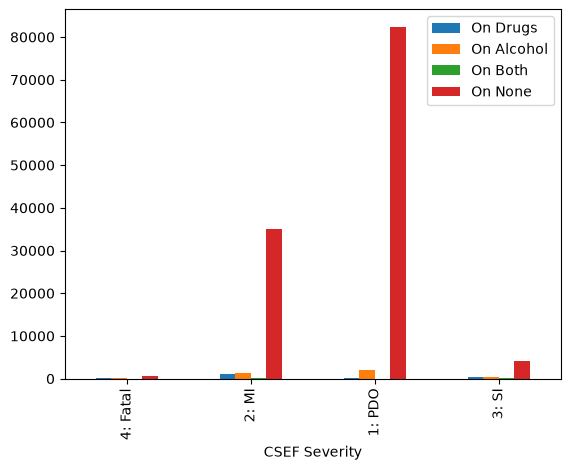

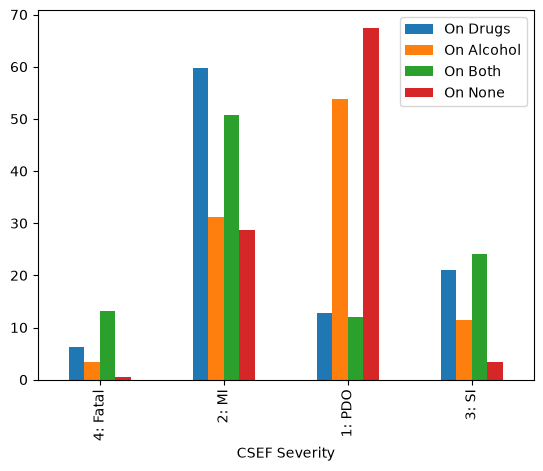

In [32]:
pd_df.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe.png')
pd_df_per.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe_per.png')

If you are confused with all the operations on PySpark DataFrames or SparkSQL then you can download my tutorial on PySpark DataFrames and SparkSQL from my [github repository](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git), jupyter notebook name is "Tutorial on PySpark DataFrames and SparkSQL" and data files required for "Tutorial on PySpark DataFrames and SparkSQL" are in the folder "data for given tutorials".

In PySpark we can implement the same queries using RDDs, DataFrame and SparkSQL. I am going to show you a few queries implemented with three different methods RDDs, DataFrame and SparkSQL.

1. Finding the Date and Time of Crash, Number of Casualties in each unit and the Gender, Age, License Type of the unit driver for the suburb “Adelaide”.

**Remarque (Windows)** — Les deux analyses RDD suivantes utilisent une jointure par *broadcast* pour contourner les plantages des workers observés avec `RDD.join()`. Les versions DataFrame et SparkSQL sont conservées pour comparaison.

In [33]:
# Transformation des lignes en (REPORT_ID, données)
def parseKey(line):
    values = next(csv.reader([line]))
    return (values[0], values[1:])

units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)

# Filtrer Adelaide avant la jointure
crash_adelaide = crash_rdd1.filter(
    lambda x: len(x[1]) > 12 and x[1][1] == 'ADELAIDE'
)

# Jointure par broadcast pour éviter le plantage
crash_dict = defaultdict(list)

for report_id, values in crash_adelaide.collect():
    crash_dict[report_id].append(values)

broadcast_crash = sc.broadcast(dict(crash_dict))

def broadcast_join(unit):
    report_id, unit_values = unit
    return [
        (report_id, (unit_values, crash_values))
        for crash_values in broadcast_crash.value.get(report_id, [])
    ]

joined_rdd = units_rdd1.flatMap(broadcast_join)

# Transformation des données
def parseRecord1(line):
    if line[1][1][1] == 'ADELAIDE':
        array_line = []
        array_line.append(line[1][1][1])
        array_line.append(line[1][0][7])
        array_line.append(line[1][0][8])
        array_line.append(line[1][0][11])
        array_line.append(line[1][1][12])
        array_line.append(line[1][1][6])
        array_line.append(
            line[1][1][9] + "-" +
            line[1][1][10] + "-" +
            line[1][1][11]
        )
        return array_line

pharsed_rdd = joined_rdd.map(parseRecord1)
filtered_pharsed_rdd = pharsed_rdd.filter(lambda x: x is not None)

filtered_pharsed_rdd.collect()

[['ADELAIDE',
  '084',
  'SA',
  'Not Towing',
  '08:45 am',
  '0',
  '2012-January-Monday'],
 ['ADELAIDE',
  '040',
  'SA',
  'Not Towing',
  '08:45 am',
  '0',
  '2012-January-Monday'],
 ['ADELAIDE', '047', 'SA', 'Unknown', '05:45 pm', '0', '2012-January-Friday'],
 ['ADELAIDE', 'XXX', '', '', '05:45 pm', '0', '2012-January-Friday'],
 ['ADELAIDE',
  '018',
  'SA',
  'Not Towing',
  '07:30 pm',
  '0',
  '2012-January-Friday'],
 ['ADELAIDE',
  '020',
  'SA',
  'Not Towing',
  '07:30 pm',
  '0',
  '2012-January-Friday'],
 ['ADELAIDE',
  '024',
  'SA',
  'Not Towing',
  '08:00 am',
  '0',
  '2012-January-Saturday'],
 ['ADELAIDE', '025', '', '', '08:00 am', '0', '2012-January-Saturday'],
 ['ADELAIDE',
  '020',
  'SA',
  'Not Towing',
  '10:20 pm',
  '0',
  '2012-January-Saturday'],
 ['ADELAIDE',
  '033',
  'SA',
  'Not Towing',
  '10:20 pm',
  '0',
  '2012-January-Saturday'],
 ['ADELAIDE',
  '064',
  'SA',
  'Unknown',
  '06:10 pm',
  '0',
  '2012-January-Wednesday'],
 ['ADELAIDE', '026', 

In [34]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
def find_date(d,m,y):
    return y + "-" + m + "-" + d
    
find_date_udf = udf(find_date)
joined_date_df = joined_df.withColumn('Date',find_date_udf('Day', 'Month', 'Year'))
joined_date_df = joined_date_df.filter(col("Suburb") == 'ADELAIDE')
joined_date_df.select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb').collect()

[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Male', Age='020', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Female', Age='024', Licence Type='Provisional 1 ', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Male', Age='025', 

In [35]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT (Year || '-' || Month || '-' || Day) as Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  where c.Suburb == 'ADELAIDE'
''')
joined_table.collect()

[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Male', Age='020', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Female', Age='024', Licence Type='Provisional 1 ', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Male', Age='025', 

2. Finding the total number of casualties for each suburb when the vehicle was driven by an unlicensed driver.

In [36]:
# RDD implementation
def parseKey(line):
    values = next(csv.reader([line]))
    return (values[0], values[1:])

units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)

# Préparer les données pour le broadcast
# Conserver uniquement REPORT_ID, Suburb et Total Cas
crash_data = crash_rdd1.map(
    lambda x: (x[0], x[1][1], x[1][5])
).collect()

crash_dict = defaultdict(list)

for report_id, suburb, total_cas in crash_data:
    crash_dict[report_id].append((suburb, total_cas))

broadcast_crash = sc.broadcast(dict(crash_dict))

# Filtrage identique à celui de ton code initial
def valid_unit(x):
    u = x[1]
    return (
        len(u) > 11
        and u[9] != "XX"
        and u[8] != "UNKNOWN"
        and u[10] != "Unknown"
        and u[9] is not None
        and u[10] is not None
        and u[11] is not None
    )

filtered_rdd = units_rdd1.filter(valid_unit)

# Jointure par broadcast et transformation
def parseRecord2(unit):
    report_id = unit[0]

    return [
        (suburb, int(total_cas))
        for suburb, total_cas in broadcast_crash.value.get(report_id, [])
    ]

pharased_filtered_rdd = filtered_rdd.flatMap(parseRecord2)

# Regrouper et sommer par Suburb
result = pharased_filtered_rdd.reduceByKey(lambda a, b: a + b)

result.collect()

[('STEPNEY', 392),
 ('MELROSE PARK', 242),
 ('REGENCY PARK', 320),
 ('SALISBURY SOUTH', 170),
 ('MARRYATVILLE', 116),
 ('WOODVILLE NORTH', 362),
 ('PARADISE', 649),
 ('SOMERTON PARK', 190),
 ('PARALOWIE', 577),
 ('GLENELG EAST', 332),
 ('POORAKA', 832),
 ('LOCKLEYS', 263),
 ('GILLES PLAINS', 202),
 ('MANNINGHAM', 241),
 ('BEVERLEY', 214),
 ('PAYNEHAM', 373),
 ('WINGFIELD', 634),
 ('VIRGINIA', 365),
 ('WYNN VALE', 309),
 ('UNLEY', 353),
 ('GOODWOOD', 111),
 ('SURREY DOWNS', 84),
 ('BOWDEN', 97),
 ('GAWLER SOUTH', 186),
 ('ST PETERS', 185),
 ('SEFTON PARK', 152),
 ('MOANA', 44),
 ('GLENELG SOUTH', 149),
 ('STIRLING', 247),
 ('WESTBOURNE PARK', 291),
 ('STRATHALBYN', 224),
 ('ASHTON', 56),
 ('COLLINSWOOD', 145),
 ('TAILEM BEND', 115),
 ('SELLICKS HILL', 162),
 ('NETHERBY', 81),
 ('CULTANA', 15),
 ('REYNELLA', 189),
 ('PARK HOLME', 288),
 ('MODBURY NORTH', 374),
 ('NETLEY', 95),
 ('RENMARK', 179),
 ('CHANDLERS HILL', 140),
 ('RICHMOND', 280),
 ('NANTAWARRA', 22),
 ('ROWLAND FLAT', 31),
 ('

In [37]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
without_lic_df = joined_df.dropna(subset=('Licence Type','Licence Class', 'Lic State'), how='all')
by_suburb_no_lic_no_df = without_lic_df.filter((col('Licence Type') != 'Unknown') &(col('Licence Class') != 'XX') &(col('Lic State') != 'UNKNOWN')).groupby('Suburb').agg(F.count('No Of Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.collect()

[Row(Suburb='FLINDERS PARK', Total casualty=620),
 Row(Suburb='TEA TREE GULLY', Total casualty=185),
 Row(Suburb='HACKHAM', Total casualty=179),
 Row(Suburb='SALT CREEK', Total casualty=22),
 Row(Suburb='CUMMINS', Total casualty=31),
 Row(Suburb='WISANGER', Total casualty=11),
 Row(Suburb='MEDINDIE GARDENS', Total casualty=80),
 Row(Suburb='BASKET RANGE', Total casualty=69),
 Row(Suburb='GILLES PLAINS', Total casualty=473),
 Row(Suburb='STANSBURY', Total casualty=30),
 Row(Suburb='MUNDOORA', Total casualty=11),
 Row(Suburb='MURRAY BRIDGE SOUTH', Total casualty=13),
 Row(Suburb='MANNA HILL', Total casualty=3),
 Row(Suburb='MONASH', Total casualty=88),
 Row(Suburb='MAGILL', Total casualty=561),
 Row(Suburb='GLENCOE', Total casualty=17),
 Row(Suburb='WHITE HILL', Total casualty=20),
 Row(Suburb='ORROROO', Total casualty=14),
 Row(Suburb='ECHUNGA', Total casualty=181),
 Row(Suburb='SPENCE', Total casualty=2),
 Row(Suburb='SCEALE BAY', Total casualty=4),
 Row(Suburb='OODLA WIRRA', Total cas

In [38]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT Suburb, COUNT(`Total Cas`)
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  WHERE `Lic State` IS NOT NULL and `Licence Class` IS NOT NULL and `Licence Type` IS NOT NULL and
  `Licence Type` != 'Unknown' and
  `Licence Class` != 'XX' and
  `Lic State` != 'UNKNOWN'
GROUP BY Suburb
''')
joined_table.collect()

[Row(Suburb='FLINDERS PARK', count(Total Cas)=620),
 Row(Suburb='TEA TREE GULLY', count(Total Cas)=185),
 Row(Suburb='HACKHAM', count(Total Cas)=179),
 Row(Suburb='SALT CREEK', count(Total Cas)=22),
 Row(Suburb='CUMMINS', count(Total Cas)=31),
 Row(Suburb='WISANGER', count(Total Cas)=11),
 Row(Suburb='MEDINDIE GARDENS', count(Total Cas)=80),
 Row(Suburb='BASKET RANGE', count(Total Cas)=69),
 Row(Suburb='GILLES PLAINS', count(Total Cas)=473),
 Row(Suburb='STANSBURY', count(Total Cas)=30),
 Row(Suburb='MUNDOORA', count(Total Cas)=11),
 Row(Suburb='MURRAY BRIDGE SOUTH', count(Total Cas)=13),
 Row(Suburb='MANNA HILL', count(Total Cas)=3),
 Row(Suburb='MONASH', count(Total Cas)=88),
 Row(Suburb='MAGILL', count(Total Cas)=561),
 Row(Suburb='GLENCOE', count(Total Cas)=17),
 Row(Suburb='WHITE HILL', count(Total Cas)=20),
 Row(Suburb='ORROROO', count(Total Cas)=14),
 Row(Suburb='ECHUNGA', count(Total Cas)=181),
 Row(Suburb='SPENCE', count(Total Cas)=2),
 Row(Suburb='SCEALE BAY', count(Total Cas

---

## Analyses complémentaires des accidents routiers (2012–2019)

Ces trois analyses utilisent **`crash_df` uniquement** (une ligne par accident, identifiée par `REPORT_ID`) pour éviter le double comptage provoqué par les jointures avec les véhicules (`units_df`). Les résultats sont agrégés avec **PySpark DataFrame** ; seules les petites tables de synthèse sont converties en Pandas pour les graphiques.

Les colonnes employées sont : `Year`, `Day`, `Time`, `Total Cas`, `Total Fats`, `Weather Cond`, `DayNight`, `Area Speed` et `CSEF Severity`.

> **Remarque :** `Day` correspond au jour de la semaine, et non à une date précise. `Area Speed` correspond à la limitation de vitesse de la zone, pas à la vitesse réelle du véhicule.

In [39]:
# Préparation commune aux trois analyses
# Les nombres sont chargés comme chaînes dans le CSV : conversion prudente.
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt


def entier_ou_null(nom_colonne):
    texte = F.trim(F.col(nom_colonne).cast("string"))
    return F.when(texte.rlike(r"^[0-9]+$"), texte.cast("int"))


crash_analyse = (
    crash_df
    .filter(F.col("REPORT_ID").isNotNull() & (F.trim(F.col("REPORT_ID")) != ""))
    .dropDuplicates(["REPORT_ID"])
    .withColumn("Annee", entier_ou_null("Year"))
    .withColumn("Deces", entier_ou_null("Total Fats"))
    .withColumn("Victimes", entier_ou_null("Total Cas"))
    .filter(F.col("Annee").between(2012, 2019))
)

print("Données préparées : accidents uniques de 2012 à 2019.")

Données préparées : accidents uniques de 2012 à 2019.


### 1. Évolution annuelle des accidents, des décès et des victimes

Compter les accidents distincts par année, puis sommer `Total Fats` et `Total Cas`. Les trois séries sont représentées séparément, car leurs ordres de grandeur diffèrent. Les valeurs manquantes dans les totaux ne sont pas interprétées comme des événements supplémentaires.

+-----+---------+-----+--------+
|Annee|Accidents|Deces|Victimes|
+-----+---------+-----+--------+
|2012 |22829    |94   |7479    |
|2013 |16675    |97   |7177    |
|2014 |16162    |108  |6982    |
|2015 |15431    |102  |6660    |
|2016 |16775    |86   |6565    |
|2017 |13237    |100  |6237    |
|2018 |13599    |80   |6124    |
|2019 |12964    |114  |6031    |
+-----+---------+-----+--------+



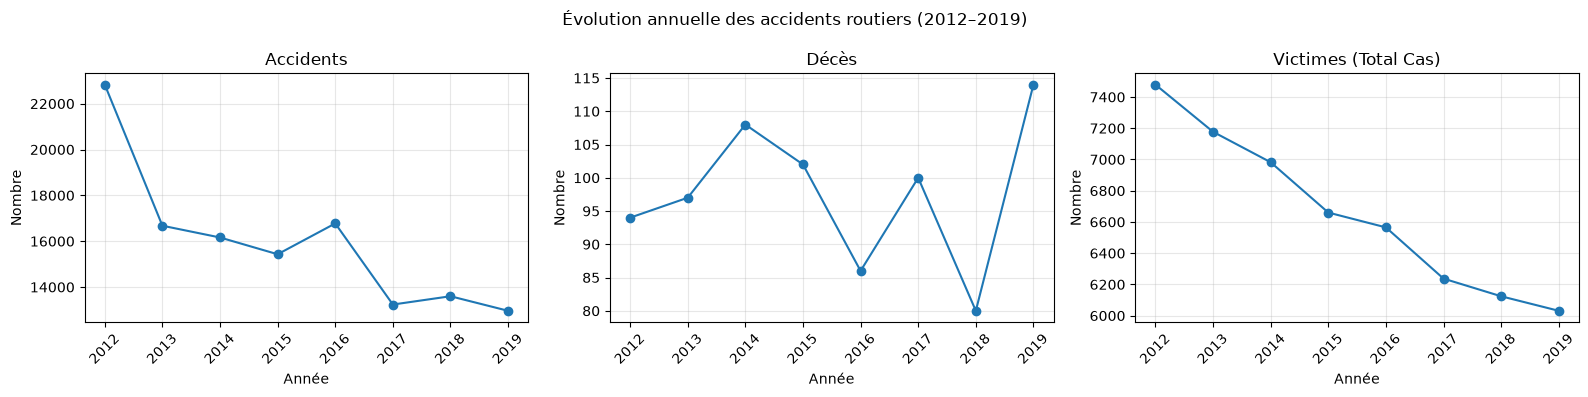

In [40]:
evolution_annuelle = (
    crash_analyse
    .groupBy("Annee")
    .agg(
        F.count("REPORT_ID").alias("Accidents"),
        F.sum("Deces").alias("Deces"),
        F.sum("Victimes").alias("Victimes"),
    )
    .orderBy("Annee")
)

evolution_annuelle.show(20, truncate=False)
evolution_pd = evolution_annuelle.toPandas().sort_values("Annee")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, colonne, titre in zip(
    axes,
    ["Accidents", "Deces", "Victimes"],
    ["Accidents", "Décès", "Victimes (Total Cas)"],
):
    ax.plot(evolution_pd["Annee"], evolution_pd[colonne], marker="o")
    ax.set_title(titre)
    ax.set_xlabel("Année")
    ax.set_ylabel("Nombre")
    ax.set_xticks(evolution_pd["Annee"].tolist())
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

fig.suptitle("Évolution annuelle des accidents routiers (2012–2019)")
plt.tight_layout()
plt.show()

### 2. Jours et heures les plus accidentogènes

Une carte de chaleur indique le **nombre d'accidents** pour chaque combinaison de jour de semaine et d'heure (0 à 23). Les horaires du CSV sont généralement au format `04:30 pm` : ils sont convertis en format 24 heures. Les horaires absents ou illisibles ne sont pas inclus dans cette analyse.

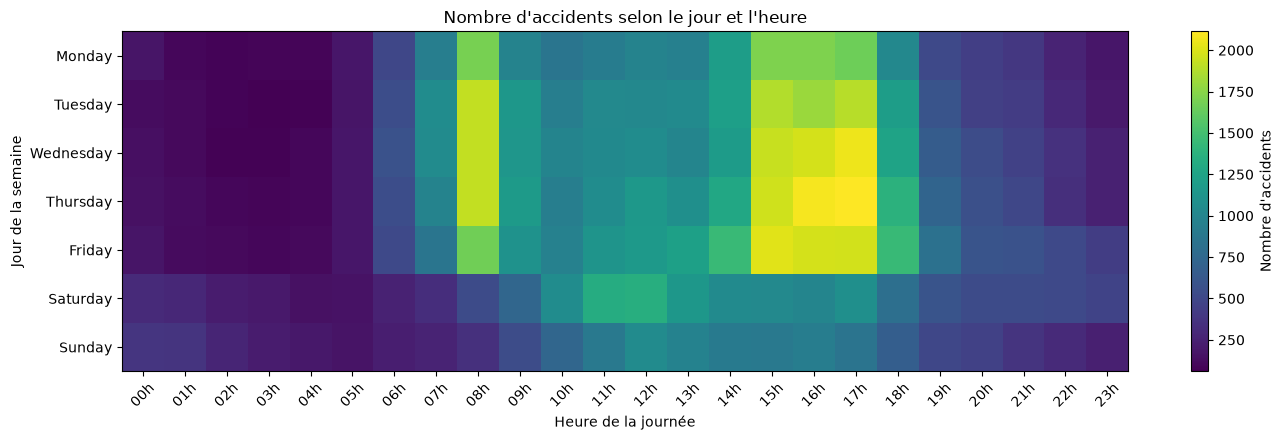

Combinaisons jour-heure les plus fréquentes :
+---------+-----+---------+
|Jour     |Heure|Accidents|
+---------+-----+---------+
|Thursday |17   |2114     |
|Thursday |16   |2087     |
|Wednesday|17   |2065     |
|Friday   |15   |2021     |
|Friday   |16   |1981     |
|Wednesday|16   |1979     |
|Friday   |17   |1974     |
|Thursday |15   |1963     |
|Wednesday|15   |1945     |
|Wednesday|8    |1927     |
+---------+-----+---------+
only showing top 10 rows


In [41]:
jours_semaine = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]

heure_texte = F.lower(F.trim(F.col("Time")))
heure_am_pm_texte = F.regexp_extract(
    heure_texte, r"^([0-9]{1,2}):[0-5][0-9]\s*(am|pm)$", 1
)
periode = F.regexp_extract(
    heure_texte, r"^([0-9]{1,2}):[0-5][0-9]\s*(am|pm)$", 2
)
heure_12 = F.when(
    F.length(heure_am_pm_texte) > 0, heure_am_pm_texte.cast("int")
)
heure_24_am_pm = F.when(
    heure_12.between(1, 12),
    F.pmod(heure_12, F.lit(12)) + F.when(periode == "pm", 12).otherwise(0)
)

# Le format HH:MM sur 24 heures est accepté également.
heure_24_texte = F.regexp_extract(
    heure_texte, r"^([01]?[0-9]|2[0-3]):[0-5][0-9]$", 1
)
heure_24_direct = F.when(F.length(heure_24_texte) > 0, heure_24_texte.cast("int"))

accidents_par_heure = (
    crash_analyse
    .withColumn("Jour", F.initcap(F.trim(F.col("Day"))))
    .withColumn("Heure", F.coalesce(heure_24_am_pm, heure_24_direct))
    .filter(F.col("Jour").isin(*jours_semaine) & F.col("Heure").between(0, 23))
    .groupBy("Jour", "Heure")
    .agg(F.count("REPORT_ID").alias("Accidents"))
)

heures_pd = accidents_par_heure.toPandas()
matrice = (
    heures_pd.pivot(index="Jour", columns="Heure", values="Accidents")
    .reindex(index=jours_semaine, columns=range(24))
    .fillna(0)
    .astype(int)
)

fig, ax = plt.subplots(figsize=(14, 4.5))
image = ax.imshow(matrice.to_numpy(), aspect="auto", interpolation="nearest")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}h" for h in range(24)], rotation=45)
ax.set_yticks(range(7))
ax.set_yticklabels(jours_semaine)
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Jour de la semaine")
ax.set_title("Nombre d'accidents selon le jour et l'heure")
fig.colorbar(image, ax=ax, label="Nombre d'accidents")
plt.tight_layout()
plt.show()

print("Combinaisons jour-heure les plus fréquentes :")
accidents_par_heure.orderBy(F.desc("Accidents")).show(10, truncate=False)

### 3. Gravité selon la météo, l'éclairage et la limitation de vitesse

On considère un accident **grave ou mortel** lorsque `CSEF Severity` vaut `3: SI` (*serious injury*) ou `4: Fatal`. Le graphique compare, pour chaque catégorie, le **pourcentage d'accidents graves ou mortels**, avec l'effectif d'accidents (`n`) affiché à côté.

- `Weather Cond` : conditions météorologiques.
- `DayNight` : conditions de luminosité (jour, nuit, etc.).
- `Area Speed` : limitation de vitesse de la zone, en km/h (et non vitesse réellement pratiquée).

Pour limiter les taux trompeurs, seules les catégories comportant **au moins 30 accidents** sont affichées ; les vitesses nulles, invraisemblables ou non numériques sont exclues. Les associations observées ne prouvent pas une causalité.

Météo :
+-----------+---------+----------------+--------------+
|Categorie  |Accidents|Accidents_graves|Taux_grave_pct|
+-----------+---------+----------------+--------------+
|Not Raining|115956   |5145            |4.44          |
|Raining    |11268    |422             |3.75          |
+-----------+---------+----------------+--------------+

Luminosité :
+---------+---------+----------------+--------------+
|Categorie|Accidents|Accidents_graves|Taux_grave_pct|
+---------+---------+----------------+--------------+
|Daylight |98724    |3890            |3.94          |
|Night    |28948    |1707            |5.9           |
+---------+---------+----------------+--------------+

Limitation de vitesse :
+---------+---------+----------------+--------------+
|Categorie|Accidents|Accidents_graves|Taux_grave_pct|
+---------+---------+----------------+--------------+
|10       |47       |12              |25.53         |
|20       |57       |6               |10.53         |
|25       |476      |13

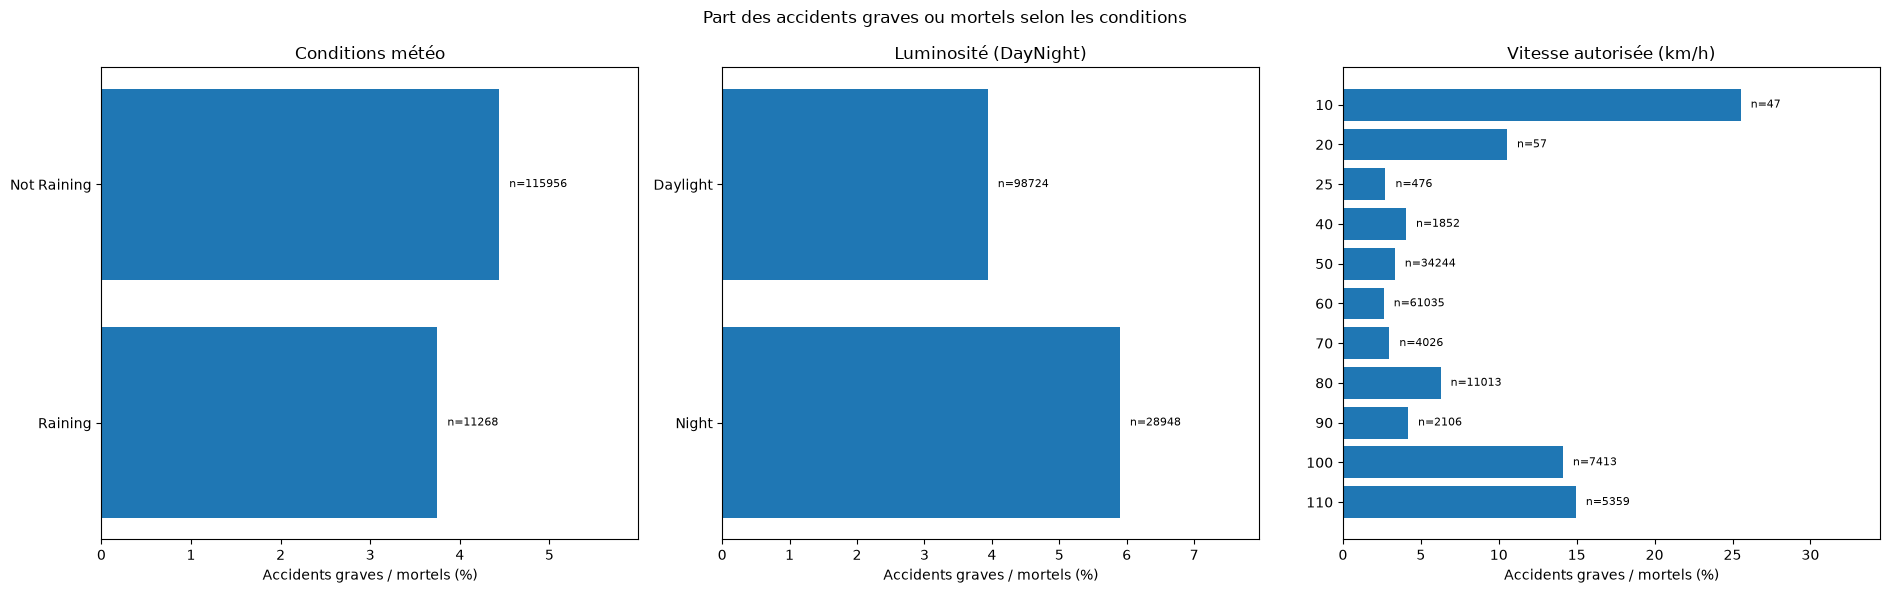

In [42]:
# Classification de la gravité à partir des valeurs documentées dans le notebook.
accidents_gravite = (
    crash_analyse
    .filter(F.col("CSEF Severity").isin("1: PDO", "2: MI", "3: SI", "4: Fatal"))
    .withColumn(
        "Grave_ou_mortel",
        F.when(F.col("CSEF Severity").isin("3: SI", "4: Fatal"), 1).otherwise(0)
    )
)


def taux_gravite_par_categorie(df, nom_colonne, effectif_min=30):
    """Calcule l'effectif et la part d'accidents graves/mortels par catégorie."""
    return (
        df.withColumn("Categorie", F.trim(F.col(nom_colonne).cast("string")))
        .filter(F.col("Categorie").isNotNull() & (F.length("Categorie") > 0))
        .filter(~F.lower(F.col("Categorie")).isin("unknown", "not known", "not applicable"))
        .groupBy("Categorie")
        .agg(
            F.count("REPORT_ID").alias("Accidents"),
            F.sum("Grave_ou_mortel").alias("Accidents_graves"),
        )
        .filter(F.col("Accidents") >= effectif_min)
        .withColumn(
            "Taux_grave_pct",
            F.round(100.0 * F.col("Accidents_graves") / F.col("Accidents"), 2)
        )
        .orderBy(F.desc("Accidents"))
    )


meteo_stats = taux_gravite_par_categorie(accidents_gravite, "Weather Cond")
luminosite_stats = taux_gravite_par_categorie(accidents_gravite, "DayNight")

vitesse_stats = taux_gravite_par_categorie(
    accidents_gravite
    .withColumn("Vitesse_kmh", entier_ou_null("Area Speed"))
    .filter(F.col("Vitesse_kmh").between(10, 130)),
    "Vitesse_kmh"
).orderBy(F.col("Categorie").cast("int"))

print("Météo :")
meteo_stats.show(truncate=False)
print("Luminosité :")
luminosite_stats.show(truncate=False)
print("Limitation de vitesse :")
vitesse_stats.show(truncate=False)

meteo_pd = meteo_stats.toPandas().head(8)
luminosite_pd = luminosite_stats.toPandas().head(8)
vitesse_pd = vitesse_stats.toPandas()


def tracer_taux_gravite(ax, tableau, titre):
    if tableau.empty:
        ax.text(0.5, 0.5, "Aucune catégorie exploitable", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(titre)
        return

    valeurs = tableau["Taux_grave_pct"].astype(float).tolist()
    positions = list(range(len(tableau)))
    ax.barh(positions, valeurs)
    ax.set_yticks(positions)
    ax.set_yticklabels(tableau["Categorie"].astype(str))
    ax.invert_yaxis()
    ax.set_xlabel("Accidents graves / mortels (%)")
    ax.set_title(titre)
    maximum = max(max(valeurs), 1.0)
    ax.set_xlim(0, maximum * 1.35)
    for position, taux, effectif in zip(positions, valeurs, tableau["Accidents"]):
        ax.text(taux + maximum * 0.025, position, f"n={int(effectif)}", va="center", fontsize=8)


fig, axes = plt.subplots(1, 3, figsize=(19, 6))
tracer_taux_gravite(axes[0], meteo_pd, "Conditions météo")
tracer_taux_gravite(axes[1], luminosite_pd, "Luminosité (DayNight)")
tracer_taux_gravite(axes[2], vitesse_pd, "Vitesse autorisée (km/h)")
fig.suptitle("Part des accidents graves ou mortels selon les conditions")
plt.tight_layout()
plt.show()